# 5.1 Concept Drift

In real-world data streams, relationships between input variables and target outcomes often change over time.
**Concept drift** occurs when the statistical properties of the target variable — or its relationship with input features — shift over time.

Common examples include:
- Changing customer preferences in online stores  
- Evolving climate patterns affecting disaster frequencies  
- Economic or policy changes influencing reported damages

If not detected and addressed, concept drift can make previously trained models **less accurate** for future predictions.

In [1]:
# %pip install geopandas geodatasets

In [ ]:
from pathlib import Path

candidate_paths = [
  Path("configs/visualisations.mplstyle"),
  Path("05_Solution_5/configs/visualisations.mplstyle"),
]

data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
  raise FileNotFoundError("Could not find configs/visualisations.mplstyle. Start Jupyter in the repository root or 05_Solution_5.")

print(f"Loading: {data_path.resolve()}")

In [3]:
import matplotlib.pyplot as plt
import numpy as np
# import custom data handling function from src folder
from src.data_handling import _load_NASA_data
# set custom plotting style
plt.style.use(str(data_path.resolve()))
# import custom visualization function from src folder
from src.visual_helper import defined_colors

## Dataset Overview

In this exercise, we use a NASA disaster dataset that records various disaster events, their characteristics, affected regions, years, and estimated damages in USD.  
Each record typically contains:
- **Location and date** of the event  
- **Disaster type** (e.g., flood, earthquake, cyclone)  
- **Socioeconomic indicators** (e.g., affected population, deaths)  
- **Economic impact** (`Total Damages (US$)`)

This data allows us to explore **temporal patterns** and how the relationships between variables (features and outcomes) may evolve over time.

In [4]:
df = _load_NASA_data()
df.head()

,Year,Seq,Glide,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,Disaster Subsubtype,Event Name,Country,...,Total Affected,Insured Damages ('000 US$),Total Damages ('000 US$),CPI,Adm Level,Admin1 Code,Admin2 Code,Geo Locations,Total Damages (US$),date
0,1900,9002,<NA>,Natural,Climatological,Drought,Drought,<NA>,<NA>,Cabo Verde,...,<NA>,<NA>,<NA>,3.221647,<NA>,<NA>,<NA>,<NA>,<NA>,1900-01-01
1,1900,9001,<NA>,Natural,Climatological,Drought,Drought,<NA>,<NA>,India,...,<NA>,<NA>,<NA>,3.221647,<NA>,<NA>,<NA>,<NA>,<NA>,1900-01-01
2,1902,12,<NA>,Natural,Geophysical,Earthquake,Ground movement,<NA>,<NA>,Guatemala,...,<NA>,<NA>,25000,3.350513,<NA>,<NA>,<NA>,<NA>,25000000,1902-04-18
3,1902,3,<NA>,Natural,Geophysical,Volcanic activity,Ash fall,<NA>,Santa Maria,Guatemala,...,<NA>,<NA>,<NA>,3.350513,<NA>,<NA>,<NA>,<NA>,<NA>,1902-04-08
4,1902,10,<NA>,Natural,Geophysical,Volcanic activity,Ash fall,<NA>,Santa Maria,Guatemala,...,<NA>,<NA>,<NA>,3.350513,<NA>,<NA>,<NA>,<NA>,<NA>,1902-10-24


In [5]:
df.describe()

,Year,Seq,Aid Contribution,Dis Mag Value,Start Year,Start Month,Start Day,End Year,End Month,End Day,Total Deaths,No Injured,No Affected,No Homeless,Total Affected,Insured Damages ('000 US$),Total Damages ('000 US$),CPI,Total Damages (US$),date
count,16126.0,16126.0,677.0,4946.0,16126.0,15739.0,12498.0,16126.0,15418.0,12570.0,11413.0,3895.0,9220.0,2430.0,11617.0,1096.0,5245.0,15811.0,5245.0,16125
mean,1996.76479,714.78482,125413.611521,47350.380307,1996.77837,6.444374,15.233957,1996.835607,6.576728,15.77502,2842.865504,2621.101669,882361.242408,73293.13786,716508.751915,798651.42427,724783.542803,63.215103,724783542.802669,1997-04-01 20:42:54.586046
min,1900.0,1.0,1.0,-57.0,1900.0,1.0,1.0,1900.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,34.0,2.0,3.221647,2000.0,1900-01-01 00:00:00
25%,1989.0,93.0,175.0,7.0,1989.0,4.0,7.0,1989.0,4.0,8.0,6.0,14.0,1244.75,572.5,650.0,50000.0,8300.0,45.692897,8300000.0,1989-01-10 00:00:00
50%,2001.0,270.0,721.0,151.5,2001.0,7.0,15.0,2001.0,7.0,16.0,20.0,50.0,10000.0,3000.0,5965.0,172500.0,60000.0,68.415379,60000000.0,2001-10-28 00:00:00
75%,2011.0,486.0,3511.0,11296.5,2011.0,9.0,23.0,2011.0,9.0,23.0,63.0,200.0,91823.0,17500.0,58255.0,500000.0,317300.0,84.252733,317300000.0,2011-01-01 00:00:00
max,2021.0,9881.0,78000000.0,13025874.0,2021.0,12.0,31.0,2021.0,12.0,31.0,3700000.0,1800000.0,330000000.0,15850000.0,330000000.0,60000000.0,210000000.0,100.0,210000000000.0,2021-10-07 00:00:00
std,20.159065,1929.635089,2997874.554919,309424.244046,20.15571,3.393965,8.953821,20.14301,3.352965,8.865486,68605.954644,34403.426733,8573912.968597,523005.754724,7718598.339358,3057638.172632,4723130.528775,26.734285,4723130528.775434,NaN


## **TASK: Investigating Temporal Shifts**
First, try to understand the data and analyze how disaster characteristics change over time by visualizing trends in key metrics. For this purpose, focus on a specific ``Disaster Type`` (e.g., Flood) and examine how ``Total Damages (US$)`` evolves over the years.

Complete the following steps by replacing the ``None`` placeholders with the correct values and variables:
1. Filter data for a specific disaster type
2. Calculate yearly median and mean damages
3. Plot event count over time
4. Plot median damages over time
5. Boxplot of damages by decade
6. Calculate rolling mean and std deviation, and plot it

In [6]:
from scipy import stats

# Define variables to focus on
disaster_type = "Flood"
target = "Total Damages (US$)"
time_column = "Year"

In [7]:
# (1.) Filter and prepare data
# ---- YOUR CODE GOES HERE (START) ---
# Create a new dataframe for the selected disaster type
df_drift = df[df["Disaster Type"] == disaster_type].copy()
# Keep only relevant columns and drop missing values
df_drift = df_drift[[time_column, target]].dropna()
# Remove entries with non-positive damage values to avoid issues with log transformation
df_drift = df_drift[df_drift[target] > 0]  
# Apply log transformation to the target variable for better handling of skewed data
df_drift[target + " (log)"] = np.log1p(df_drift[target])
# --- YOUR CODE GOES HERE (END) ---

In [8]:
# (2.) Calculate yearly median and mean damages
# ---- YOUR CODE GOES HERE (START) ---
# Group disasters by year and calculate median and mean, and count of occurrences
yearly_stats = df_drift.groupby(time_column).agg({
    target: ['median', 'mean', 'count'],
    target + " (log)": ['median', 'mean']
}).reset_index()
# Label the columns for easier access
yearly_stats.columns = ['Year', 'Median_Damages', 'Mean_Damages', 'Count', 'Log_Median', 'Log_Mean']
# --- YOUR CODE GOES HERE (END) ---

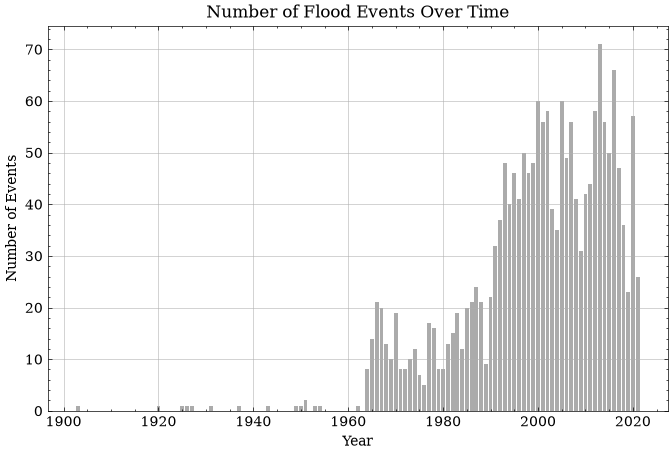

In [9]:
# (3.) Plot event count over time
plt.figure(figsize=(8, 5))
plt.bar(yearly_stats['Year'], yearly_stats['Count'],color=defined_colors[2])
plt.xlabel('Year')
plt.ylabel('Number of Events')
plt.title(f'Number of {disaster_type} Events Over Time')
plt.show()

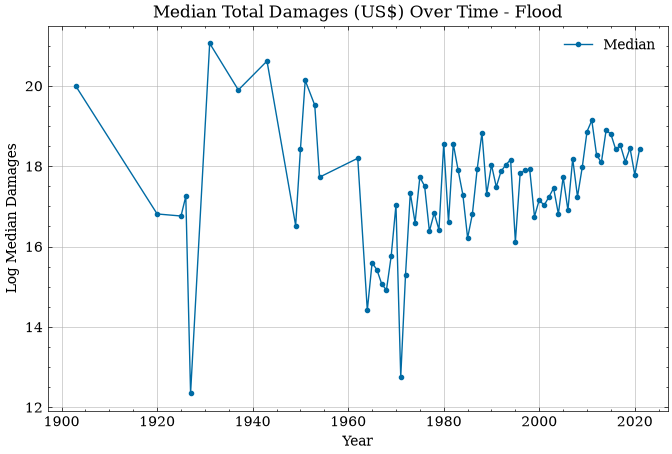

In [10]:
# (4.) Plot median damages over time
plt.figure(figsize=(8, 5))
# ---- YOUR CODE GOES HERE (START) ---
# x: Year, y: log-transformed median damages
plt.plot(yearly_stats['Year'], yearly_stats['Log_Median'], 
                marker='o', linewidth=1, markersize=3, color=defined_colors[0], label='Median')
# --- YOUR CODE GOES HERE (END) ---

# Labels for plotting
plt.xlabel('Year')
plt.ylabel('Log Median Damages')
plt.title(f'Median {target} Over Time - {disaster_type}')
plt.legend()
plt.show()

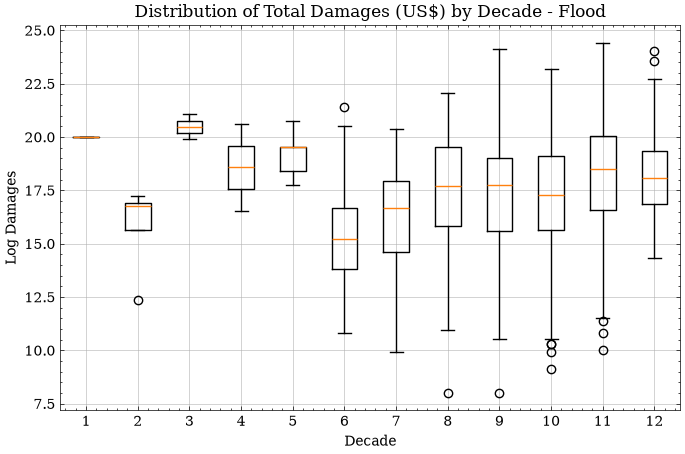

In [11]:
# (5.) Boxplot of damages by decade
plt.figure(figsize=(8, 5))
# ---- YOUR CODE GOES HERE (START) ---
# Create a 'Decade' column for grouping and sort data into decades
df_drift['Decade'] = (df_drift[time_column] // 10) * 10
decades = sorted(df_drift['Decade'].unique())
data_by_decade = [
    df_drift[df_drift['Decade'] == d][target + " (log)"].values
    for d in decades
]
# --- YOUR CODE GOES HERE (END) ---
plt.boxplot(data_by_decade, label=decades)
plt.xlabel('Decade')
plt.ylabel('Log Damages')
plt.title(f'Distribution of {target} by Decade - {disaster_type}')
plt.show()

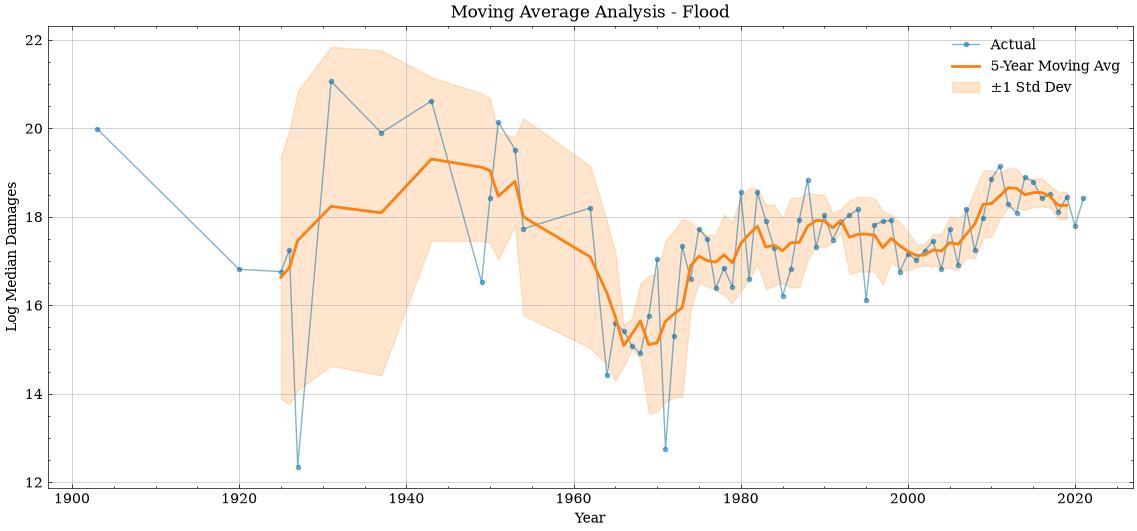

In [12]:
# (6.) Calculate rolling mean and std deviation, and plot it
# specify window size
window_size = 5

# ---- YOUR CODE GOES HERE (START) ---
# Calculate rolling mean and standard deviation for log median damages
yearly_stats['Rolling_Mean'] = yearly_stats['Log_Median'].rolling(window=window_size, center=True).mean()
yearly_stats['Rolling_Std'] = yearly_stats['Log_Median'].rolling(window=window_size, center=True).std()
# x: Year, y: log-transformed median damages with rolling statistics
plt.plot(yearly_stats['Year'], yearly_stats['Log_Median'], 
                marker='o', alpha=0.5, label='Actual', linewidth=1, color=defined_colors[0])
# x: Year, y: rolling mean with shaded std deviation
plt.plot(yearly_stats['Year'], yearly_stats['Rolling_Mean'], 
                linewidth=2, label=f'{window_size}-Year Moving Avg', color=defined_colors[1])
# Fill between rolling mean ± std deviation
plt.fill_between(yearly_stats['Year'], 
                         yearly_stats['Rolling_Mean'] - yearly_stats['Rolling_Std'],
                         yearly_stats['Rolling_Mean'] + yearly_stats['Rolling_Std'],
                         alpha=0.2, color=defined_colors[1], label='±1 Std Dev')
# --- YOUR CODE GOES HERE (END) ---

# Labels for plotting
plt.xlabel('Year')
plt.ylabel('Log Median Damages')
plt.title(f'Moving Average Analysis - {disaster_type}')
plt.legend()
plt.show()

## **TASK: Investigating Seasonality**
Now that you understand the relationship between floods and damages better, analyze recurring patterns in disaster data by examining how damages vary across different months. This helps identify seasonal patterns that might affect model predictions.

Complete the following steps by replacing the ``None`` placeholders with the correct entries:
1. Calculate statistics for each month
2. Visualize median damages and std. by month and compare to overall median
3. Describe some of the interesting patterns in your own words and propose an explanation for these patterns

In [13]:
# Define variables to focus on
disaster_type = "Flood"
target = "Total Damages (US$)"
time_column = "Start Month"

# Copy, filter, and prepare data for trend analysis
df_season = df[df["Disaster Type"] == disaster_type].copy()
df_season = df_season[[time_column, target, "Year"]].dropna()
df_season = df_season[df_season[target] > 0]
df_season[target + " (log)"] = np.log1p(df_season[target])

In [14]:
# (1.) Calculate statistics for each month
# ---- YOUR CODE GOES HERE (START) ---
# Group disasters by month and calculate median, mean, and count
monthly_stats = df_season.groupby(time_column).agg({
    target: ['median', 'mean', 'count'],
    target + " (log)": ['median', 'mean', 'std']
}).reset_index()
# Label the columns for easier access
monthly_stats.columns = ['Month', 'Median_Damages', 'Mean_Damages', 'Count', 
                          'Log_Median', 'Log_Mean', 'Log_Std']
# --- YOUR CODE GOES HERE (END) ---

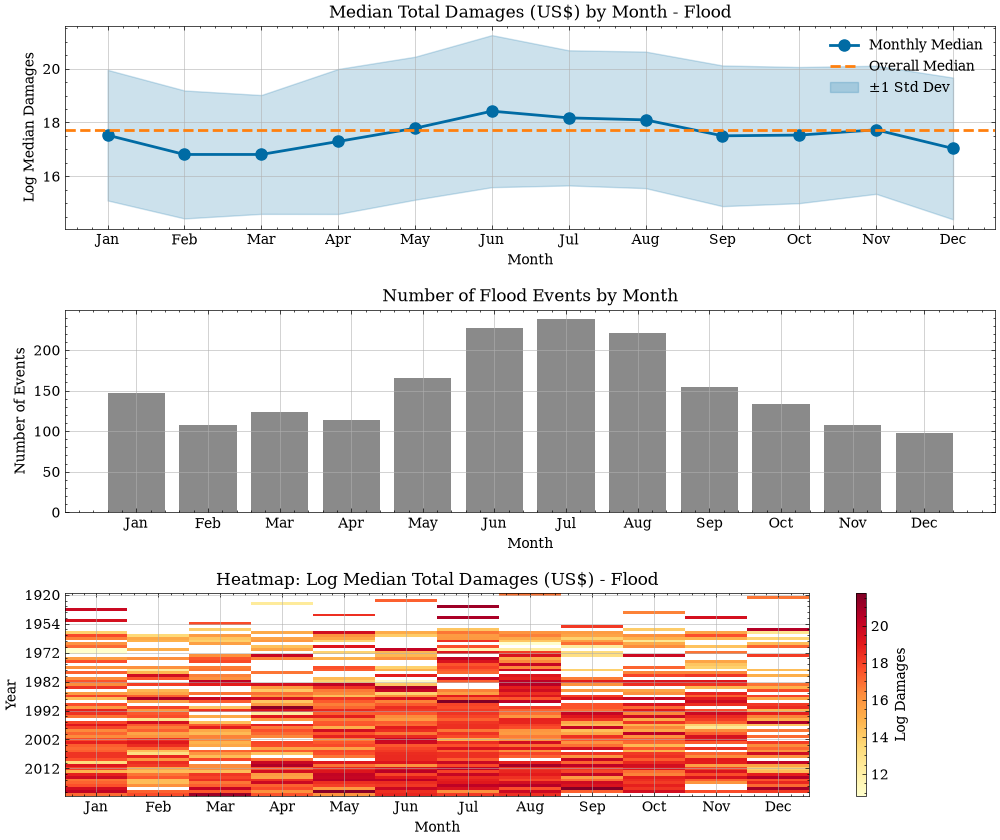

In [15]:
# (2.) Visualize median damages and std. by month and compare to overall median
# Set up subplots
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# ---- YOUR CODE GOES HERE (START) ---
# Plot 1: x: Month, y: log-transformed median damages
axes[0].plot(monthly_stats['Month'], monthly_stats['Log_Median'], 
                marker='o', linewidth=2, markersize=8, color=defined_colors[0], label='Monthly Median')
# Overall median line
overall_median = df_season[target + " (log)"].median()
axes[0].axhline(overall_median, color=defined_colors[1], linestyle='--', label='Overall Median', linewidth=2)
# Fill between monthly median ± std deviation
axes[0].fill_between(monthly_stats['Month'], 
                         monthly_stats['Log_Median'] - monthly_stats['Log_Std'],
                         monthly_stats['Log_Median'] + monthly_stats['Log_Std'],
                         alpha=0.2, color=defined_colors[0], label='±1 Std Dev')
# --- YOUR CODE GOES HERE (END) ---

# Plot 1: Median damages by month
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Log Median Damages')
axes[0].set_title(f'Median {target} by Month - {disaster_type}')
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(month_names, rotation=0)
axes[0].legend(loc='upper right')

# Plot 2: Event count by month
# x: Month, y: count of events
axes[1].bar(monthly_stats['Month'], monthly_stats['Count'], 
               alpha=0.7, color=defined_colors[3])
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Number of Events')
axes[1].set_title(f'Number of {disaster_type} Events by Month')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names, rotation=0)

# Plot 3: Heatmap Year vs Month
import numpy.ma as ma
# Prepare data for heatmap
pivot_data = df_season.groupby(['Year', time_column])[target + " (log)"].median().reset_index()
pivot_table = pivot_data.pivot(index='Year', columns=time_column, values=target + " (log)")
pivot_filled = pivot_table.fillna(np.nan)  
pivot_array = pivot_filled.to_numpy(dtype=float)
masked_data = ma.masked_invalid(pivot_array)
# Create heatmap
im = axes[2].imshow(masked_data, aspect='auto', cmap='YlOrRd', 
                        interpolation='nearest')

axes[2].set_xlabel('Month')
axes[2].set_ylabel('Year')
axes[2].set_title(f'Heatmap: Log Median {target} - {disaster_type}')
axes[2].set_xticks(range(12))
axes[2].set_xticklabels(month_names, rotation=0)
axes[2].set_yticks(range(0, len(pivot_table), 10))
axes[2].set_yticklabels(pivot_table.index[::10])
plt.colorbar(im, ax=axes[2], label='Log Damages')

plt.subplots_adjust(hspace=0.4)
plt.show()


3. Describe some of the interesting patterns in your own words and propose an explanation for these patterns


The plots show some clear seasonal patterns in flood activity and impact:  

- **Seasonality of events:** The bar chart reveals a strong concentration of flood events between **June and August**, peaking in midsummer. This likely corresponds to **rainy or monsoon seasons** in many regions, when heavy rain increases flood risk.  
- **Damages pattern:** The top plot shows that **median damages are slightly higher in summer months** (June–August) compared to winter. This may reflect that **floods during warmer months** affect more populated or economically active areas, or that heavy rainfall is more intense in this period.  
- **Heatmap variability:** The heatmap suggests that while floods occur throughout the year, the **intensity and frequency fluctuate across decades**, possibly linked to **climate change**, **increased value of damaged properties**, or **improved reporting practices**.